# Sinogram

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Define parameters

In [2]:
# --- 1. PARAMETERS ---
dims = 64
half_dims = dims / 2
target_theta_deg = 45  # The specific angle to visualize in the third subplot

# --- 2. GENERATE SHAPE (DISK) ---
y, x = np.ogrid[-dims//2:dims//2, -dims//2:dims//2]
# Disk: Radius 16
shape_img = (x**2 + y**2 <= 16**2).astype(float)

# --- 3. CALCULATE SINOGRAM (Inline Logic) ---
# Parameters for calculation
s_range = np.arange(-dims, dims + 1)
angles = np.arange(0, 180, 1)  # 1 degree steps

# Pre-calculate Rho range (depends only on dims, constant for all angles)
max_rho = int(np.ceil(dims * np.sqrt(2) / 2))
rho_values = np.arange(-max_rho, max_rho + 1)

sinogram_list = []

# Loop through every angle to build the sinogram
for ang in angles:
    theta = np.radians(ang)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    
    current_angle_projection = []
    
    # Loop through every Rho value for this angle
    for r in rho_values:
        # Coordinate transformation
        x_c = r * cos_t - s_range * sin_t + half_dims
        y_c = r * sin_t + s_range * cos_t + half_dims
        
        # Nearest neighbor interpolation (rounding indices)
        x_idx = np.round(x_c).astype(int)
        y_idx = np.round(y_c).astype(int)
        
        # Check bounds
        valid = (x_idx >= 0) & (x_idx < dims) & (y_idx >= 0) & (y_idx < dims)
        
        if np.any(valid):
            val_sum = np.sum(shape_img[y_idx[valid], x_idx[valid]])
        else:
            val_sum = 0.0
            
        current_angle_projection.append(val_sum)
    
    sinogram_list.append(current_angle_projection)

sinogram_data = np.array(sinogram_list)  # Shape: (Angles, Rhos)

# --- 4. EXTRACT SPECIFIC PROJECTION ---
# Find the index corresponding to the target theta
target_idx = np.abs(angles - target_theta_deg).argmin()
target_projection = sinogram_data[target_idx]


## Plot

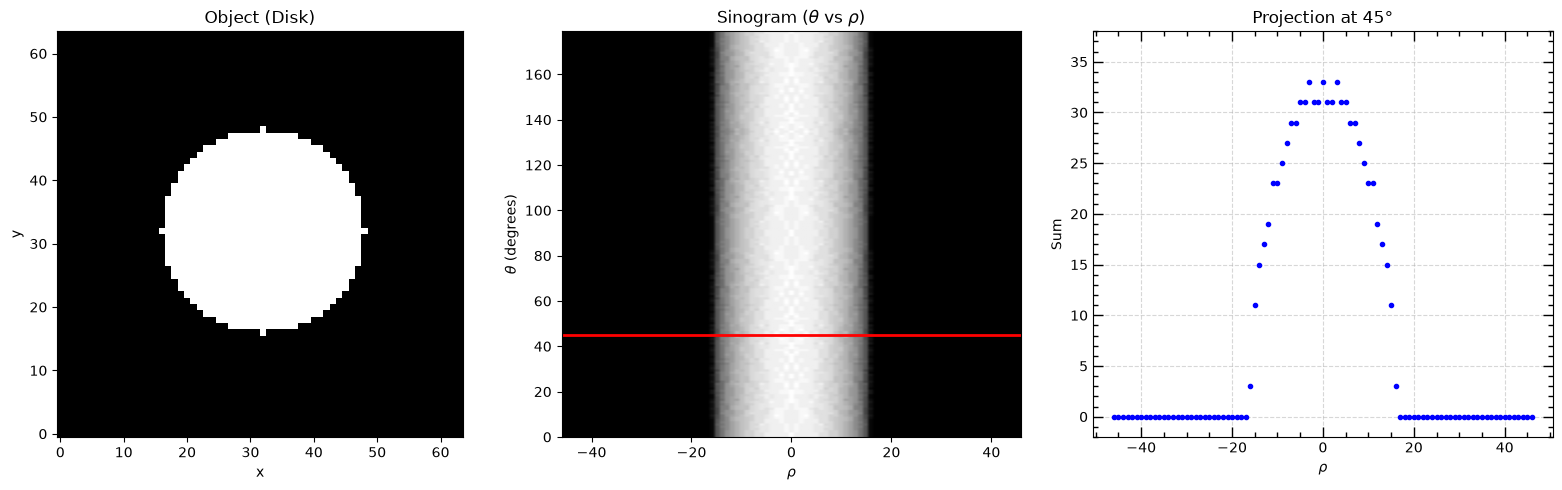

In [3]:
# --- 5. PLOTTING ---
fig1, axes1 = plt.subplots(1, 3, figsize=(16, 5))

# 1. The Shape
axes1[0].imshow(shape_img, cmap='gray', origin='lower')
axes1[0].set_title("Object (Disk)")
axes1[0].set_xlabel("x")
axes1[0].set_ylabel("y")

# 2. The Sinogram
# Note: aspect='auto' is crucial so the 180 angles don't squish the plot
axes1[1].imshow(sinogram_data, cmap='gray', aspect='auto', origin='lower',
               extent=[rho_values[0], rho_values[-1], angles[0], angles[-1]])
axes1[1].set_title(r"Sinogram ($\theta$ vs $\rho$)")
axes1[1].set_xlabel(r"$\rho$")
axes1[1].set_ylabel(r"$\theta$ (degrees)")
# Add red line to indicate current selection
axes1[1].axhline(target_theta_deg, color='red', linewidth=2)

# 3. The Projection
axes1[2].plot(rho_values, target_projection, 'o', color='blue', markersize=3)
axes1[2].set_title(f"Projection at {target_theta_deg}°")
axes1[2].set_xlabel(r"$\rho$")
axes1[2].set_ylabel("Sum")
axes1[2].set_ylim(-2, np.max(sinogram_data) + 5)
axes1[2].grid(True, linestyle='--', alpha=0.5)
axes1[2].minorticks_on()
axes1[2].tick_params(which='both',direction="in",width=1)
axes1[2].tick_params(which='major',length=7)
axes1[2].tick_params(which='minor',length=3.5)
axes1[2].xaxis.set_ticks_position('both')
axes1[2].yaxis.set_ticks_position('both')


plt.tight_layout()
plt.show()

## Use ipywidgets to interactively change shape and update the plot

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Dropdown
import ipywidgets as widgets

# --- 1. PARAMETERS & SHAPE GENERATION ---
dims2 = 64
half_dims2 = dims2 / 2
y2, x2 = np.ogrid[-dims2//2:dims2//2, -dims2//2:dims2//2]
s_range2 = np.arange(-dims2, dims2 + 1)

# Define Shapes
# Diamond intercept calculation to match Mathematica logic
diamond_intercept = 16 * np.sqrt(2) 

shapes_data = {
    'Disk': (x2**2 + y2**2 <= 16**2).astype(float),
    'Diamond': (np.abs(x2) + np.abs(y2) <= diamond_intercept).astype(float),
    'Box': ((np.abs(x2) <= 16) & (np.abs(y2) <= 16)).astype(float),
    'Diagonal': np.clip(np.eye(dims2) + np.eye(dims2, k=1) + np.eye(dims2, k=-1), 0, 1),
    'Cross': (((np.abs(x2) <= 16) & (np.abs(y2) <= 4)) | 
              ((np.abs(x2) <= 4) & (np.abs(y2) <= 16))).astype(float)
}

# --- 2. HELPER FUNCTION ---
def get_projection_at_angle(img, theta_deg):
    theta = np.radians(theta_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    
    max_rho = int(np.ceil(dims2 * np.sqrt(2) / 2))
    rho_values = np.arange(-max_rho, max_rho + 1)
    projection_sums = []
    
    for r in rho_values:
        x_c = r * cos_t - s_range2 * sin_t + half_dims2
        y_c = r * sin_t + s_range2 * cos_t + half_dims2
        
        x_idx = np.round(x_c).astype(int)
        y_idx = np.round(y_c).astype(int)
        
        valid = (x_idx >= 0) & (x_idx < dims2) & (y_idx >= 0) & (y_idx < dims2)
        if np.any(valid):
            val_sum = np.sum(img[y_idx[valid], x_idx[valid]])
        else:
            val_sum = 0.0
        projection_sums.append(val_sum)
        
    return rho_values, np.array(projection_sums)

# --- 3. PRE-CALCULATE ALL SINOGRAMS ---
# This ensures the sliders are instant. 
# We store results in a dictionary: sinogram_storage[shape_name] = (sinogram_array, rho_axis)

print("Pre-calculating sinograms for all shapes... (this may take a few seconds)")
angles2 = np.arange(0, 180, 1)
sinogram_storage = {}

for name, img in shapes_data.items():
    sinogram_list2 = []
    rho_axis = None
    for ang in angles2:
        r_vals, p_vals = get_projection_at_angle(img, ang)
        sinogram_list2.append(p_vals)
        if rho_axis is None:
            rho_axis = r_vals
    
    sinogram_storage[name] = (np.array(sinogram_list2), rho_axis)

print("Calculation complete. Rendering interactive plot...")

# --- 4. INTERACTIVE PLOT FUNCTION ---
def update_plot(shape_name, theta):
    # Retrieve data
    img = shapes_data[shape_name]
    sinogram_data, rho_axis = sinogram_storage[shape_name]
    
    # Setup Figure
    fig1, axes1 = plt.subplots(1, 3, figsize=(16, 5))
    
    # 1. The Shape
    axes1[0].imshow(img, cmap='gray', origin='lower')
    axes1[0].set_title(f"Object ({shape_name})")
    axes1[0].set_xlabel("x")
    axes1[0].set_ylabel("y")

    # 2. The Sinogram
    axes1[1].imshow(sinogram_data, cmap='gray', aspect='auto', origin='lower',
                    extent=[rho_axis[0], rho_axis[-1], angles2[0], angles2[-1]])
    axes1[1].set_title(r"Sinogram ($\theta$ vs $\rho$)")
    axes1[1].set_xlabel(r"$\rho$")
    axes1[1].set_ylabel(r"$\theta$ (degrees)")
    axes1[1].axhline(theta, color='red', linewidth=2)

    # 3. The Projection Slice
    target_idx = np.abs(angles2 - theta).argmin()
    target_projection = sinogram_data[target_idx]
    
    axes1[2].plot(rho_axis, target_projection, 'o', color='blue', markersize=3)
    axes1[2].set_title(f"Projection at {theta}°")
    axes1[2].set_xlabel(r"$\rho$")
    axes1[2].set_ylabel("Sum")
    
    # Fix Y-limit based on the specific shape's max value
    axes1[2].set_ylim(-2, np.max(sinogram_data) + 5)
    axes1[2].grid(True, linestyle='--', alpha=0.5)

    # Tick Parameters
    axes1[2].tick_params(which='both', direction="in", width=1)
    axes1[2].tick_params(which='major', length=7)
    axes1[2].tick_params(which='minor', length=3.5)
    axes1[2].xaxis.set_ticks_position('both')
    axes1[2].yaxis.set_ticks_position('both')

    plt.tight_layout()
    plt.show()

# --- 5. WIDGET SETUP ---
interact(update_plot, 
         shape_name=Dropdown(options=list(shapes_data.keys()), value='Disk', description='Shape:'),
         theta=IntSlider(min=0, max=179, step=1, value=45, description='Theta:'));

Pre-calculating sinograms for all shapes... (this may take a few seconds)


Calculation complete. Rendering interactive plot...


### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch09/ch09-02.html) (direct link: [ch09-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch09/ch09-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.